In [35]:

import pandas as pd

# Load the uploaded dataset
df = pd.read_csv('/content/Sample - Superstore.csv', encoding='latin1')

# Display the first five rows
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [36]:

import zipfile
import os

# Extract the archive ZIP folder
with zipfile.ZipFile('/content/archive.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/superstore_data')

print("ZIP folder extracted successfully!")

# Display extracted files
print(os.listdir('/content/superstore_data'))


FileNotFoundError: [Errno 2] No such file or directory: '/content/archive.zip'

In [ ]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

In [ ]:

# Check the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


In [38]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


In [39]:

# Display all column names

print("DATASET COLUMNS")

for column in df.columns:
    print(column)


DATASET COLUMNS
Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Customer Name
Segment
Country
City
State
Postal Code
Region
Product ID
Category
Sub-Category
Product Name
Sales
Quantity
Discount
Profit


In [40]:

# Examine dataset structure

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [41]:

# Check missing values

print("MISSING VALUES PER COLUMN")

print(df.isnull().sum())


MISSING VALUES PER COLUMN
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [42]:

# STEP 3.1: CONVERT DATE COLUMNS

df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    errors='coerce'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    errors='coerce'
)

print("Date conversion completed!")

print("\nOrder Date data type:", df['Order Date'].dtype)
print("Ship Date data type:", df['Ship Date'].dtype)

print("\nFirst five order dates:")
display(df[['Order Date', 'Ship Date']].head())


Date conversion completed!

Order Date data type: datetime64[ns]
Ship Date data type: datetime64[ns]

First five order dates:


,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


In [43]:

# STEP 3.2: CHECK DATE RANGE

print("Earliest order date:",
      df['Order Date'].min())

print("Latest order date:",
      df['Order Date'].max())

print("\nInvalid order dates:",
      df['Order Date'].isnull().sum())

print("Invalid shipping dates:",
      df['Ship Date'].isnull().sum())


Earliest order date: 2014-01-03 00:00:00
Latest order date: 2017-12-30 00:00:00

Invalid order dates: 0
Invalid shipping dates: 0


In [44]:

# STEP 3.3: CHECK NUMERICAL VALUES

print("Sales statistics:")
print(df['Sales'].describe())

print("\nProfit statistics:")
print(df['Profit'].describe())

print("\nQuantity statistics:")
print(df['Quantity'].describe())

print("\nNegative sales:", (df['Sales'] < 0).sum())

print("Negative quantities:", (df['Quantity'] < 0).sum())


Sales statistics:
count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64

Profit statistics:
count    9994.000000
mean       28.656896
std       234.260108
min     -6599.978000
25%         1.728750
50%         8.666500
75%        29.364000
max      8399.976000
Name: Profit, dtype: float64

Quantity statistics:
count    9994.000000
mean        3.789574
std         2.225110
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        14.000000
Name: Quantity, dtype: float64

Negative sales: 0
Negative quantities: 0


In [45]:

# STEP 3.4: CREATE TIME-BASED FEATURES

df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Month_Name'] = df['Order Date'].dt.month_name()

df['Quarter'] = df['Order Date'].dt.quarter

df['Day'] = df['Order Date'].dt.day

print("Time-based features created successfully!")

display(df[['Order Date',
            'Year',
            'Month',
            'Month_Name',
            'Quarter',
            'Day']].head())


Time-based features created successfully!


,Order Date,Year,Month,Month_Name,Quarter,Day
0,2016-11-08,2016,11,November,4,8
1,2016-11-08,2016,11,November,4,8
2,2016-06-12,2016,6,June,2,12
3,2015-10-11,2015,10,October,4,11
4,2015-10-11,2015,10,October,4,11


In [46]:

# STEP 4.1: AGGREGATE SALES BY MONTH

# Group transactions by year and month
monthly_sales = df.groupby(
    ['Year', 'Month']
)['Sales'].sum().reset_index()

# Create a proper monthly date column
monthly_sales['Date'] = pd.to_datetime(
    monthly_sales['Year'].astype(str) + '-' +
    monthly_sales['Month'].astype(str) + '-01'
)

# Sort data chronologically
monthly_sales = monthly_sales.sort_values('Date')

# Display the monthly sales
display(monthly_sales.head(12))

print("\nTotal monthly records:", len(monthly_sales))


,Year,Month,Sales,Date
0,2014,1,14236.8950,2014-01-01
1,2014,2,4519.8920,2014-02-01
2,2014,3,55691.0090,2014-03-01
3,2014,4,28295.3450,2014-04-01
4,2014,5,23648.2870,2014-05-01
5,2014,6,34595.1276,2014-06-01
6,2014,7,33946.3930,2014-07-01
7,2014,8,27909.4685,2014-08-01
8,2014,9,81777.3508,2014-09-01
9,2014,10,31453.3930,2014-10-01



Total monthly records: 48


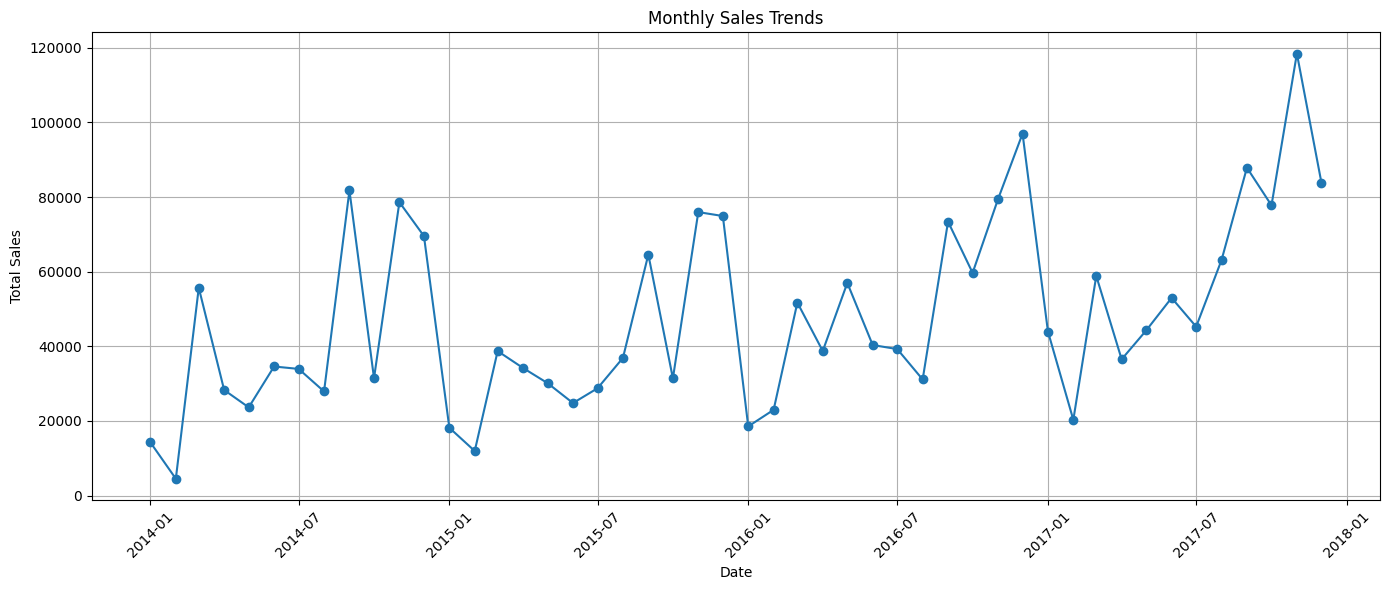

In [47]:

# STEP 4.2: VISUALIZE MONTHLY SALES

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Trends')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


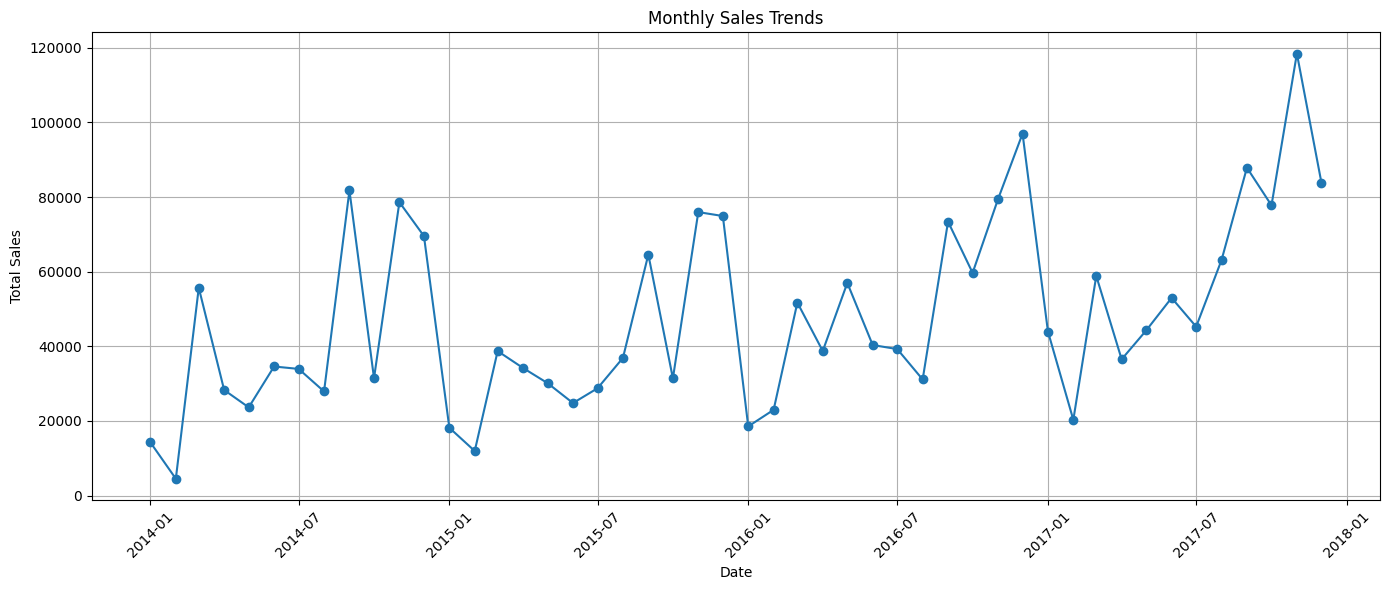

In [48]:

# STEP 4.2: VISUALIZE MONTHLY SALES

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Trends')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [52]:

# STEP 4.3: MONTHLY SALES SUMMARY

print("MONTHLY SALES SUMMARY")

print("\nAverage monthly sales:",
      round(monthly_sales['Sales'].mean(), 2))

print("\nHighest monthly sales:",
      round(monthly_sales['Sales'].max(), 2))

print("\nLowest monthly sales:",
      round(monthly_sales['Sales'].min(), 2))

print("\nTotal sales:",
      round(monthly_sales['Sales'].sum(), 2))

print("\nNumber of months:",
      len(monthly_sales))


MONTHLY SALES SUMMARY

Average monthly sales: 47858.35

Highest monthly sales: 118447.82

Lowest monthly sales: 4519.89

Total sales: 2297200.86

Number of months: 48


In [56]:

# STEP 4.4: BEST AND WORST SALES MONTHS

highest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales['Sales'].idxmin()
]

print("HIGHEST SALES MONTH")
print(highest_month)

print("\nLOWEST SALES MONTH")
print(lowest_month)


HIGHEST SALES MONTH
Year                    2017
Month                     11
Sales             118447.825
Date     2017-11-01 00:00:00
Name: 46, dtype: object

LOWEST SALES MONTH
Year                    2014
Month                      2
Sales               4519.892
Date     2014-02-01 00:00:00
Name: 1, dtype: object


YEARLY SALES SUMMARY


,Year,Sales
0,2014,484247.4981
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552


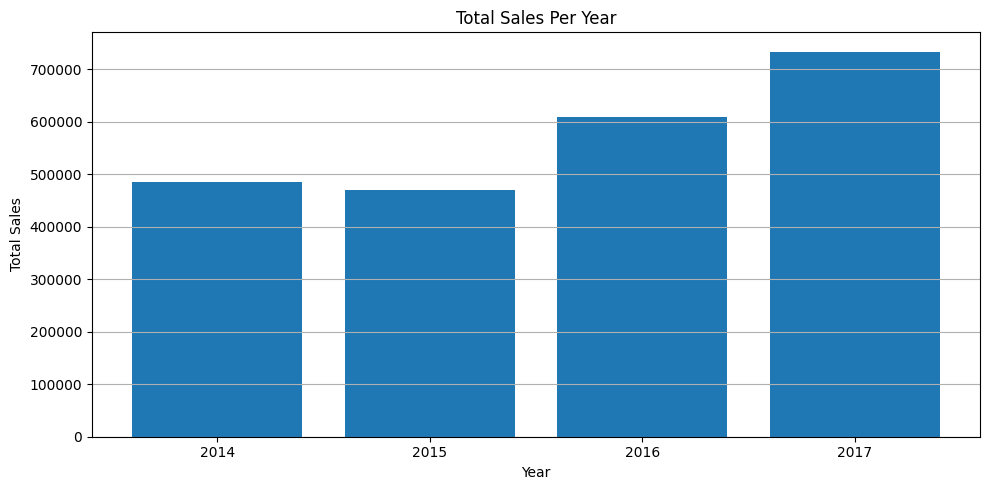

In [60]:

# STEP 5.1: YEARLY SALES ANALYSIS

yearly_sales = monthly_sales.groupby(
    'Year'
)['Sales'].sum().reset_index()

print("YEARLY SALES SUMMARY")

display(yearly_sales)

# Visualize yearly sales
plt.figure(figsize=(10, 5))

plt.bar(
    yearly_sales['Year'].astype(str),
    yearly_sales['Sales']
)

plt.title('Total Sales Per Year')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.grid(axis='y')
plt.tight_layout()
plt.show()


AVERAGE SALES BY MONTH


,Month,Sales,Month_Name
0,1,23731.208900,January
1,2,14937.812850,February
2,3,51251.372200,March
3,4,34440.532150,April
4,5,38757.202925,May
5,6,38179.669825,June
6,7,36809.524250,July
7,8,39761.015750,August
8,9,76912.486425,September
9,10,50080.746175,October


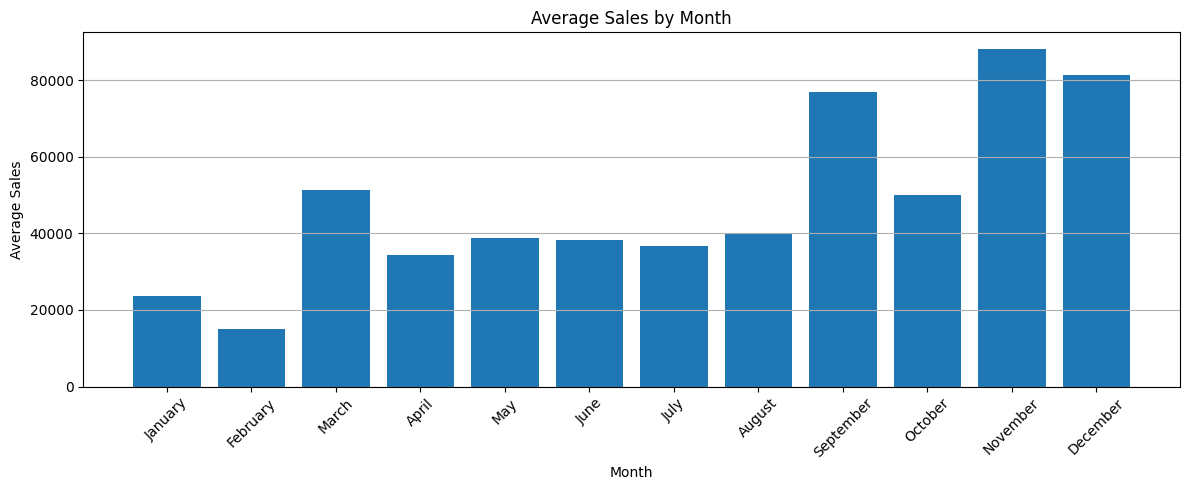

In [64]:

# STEP 5.2: MONTHLY SEASONALITY ANALYSIS

seasonal_sales = monthly_sales.groupby(
    'Month'
)['Sales'].mean().reset_index()

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

seasonal_sales['Month_Name'] = month_names

print("AVERAGE SALES BY MONTH")

display(seasonal_sales)

# Plot seasonal sales
plt.figure(figsize=(12, 5))

plt.bar(
    seasonal_sales['Month_Name'],
    seasonal_sales['Sales']
)

plt.title('Average Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Sales')

plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [68]:

# STEP 5.3: BEST AND WORST MONTHS

best_month = seasonal_sales.loc[
    seasonal_sales['Sales'].idxmax()
]

worst_month = seasonal_sales.loc[
    seasonal_sales['Sales'].idxmin()
]

print("BEST PERFORMING MONTH:")
print(best_month)

print("\nLOWEST PERFORMING MONTH:")
print(worst_month)


BEST PERFORMING MONTH:
Month                  11
Sales         88115.26775
Month_Name       November
Name: 10, dtype: object

LOWEST PERFORMING MONTH:
Month                   2
Sales         14937.81285
Month_Name       February
Name: 1, dtype: object


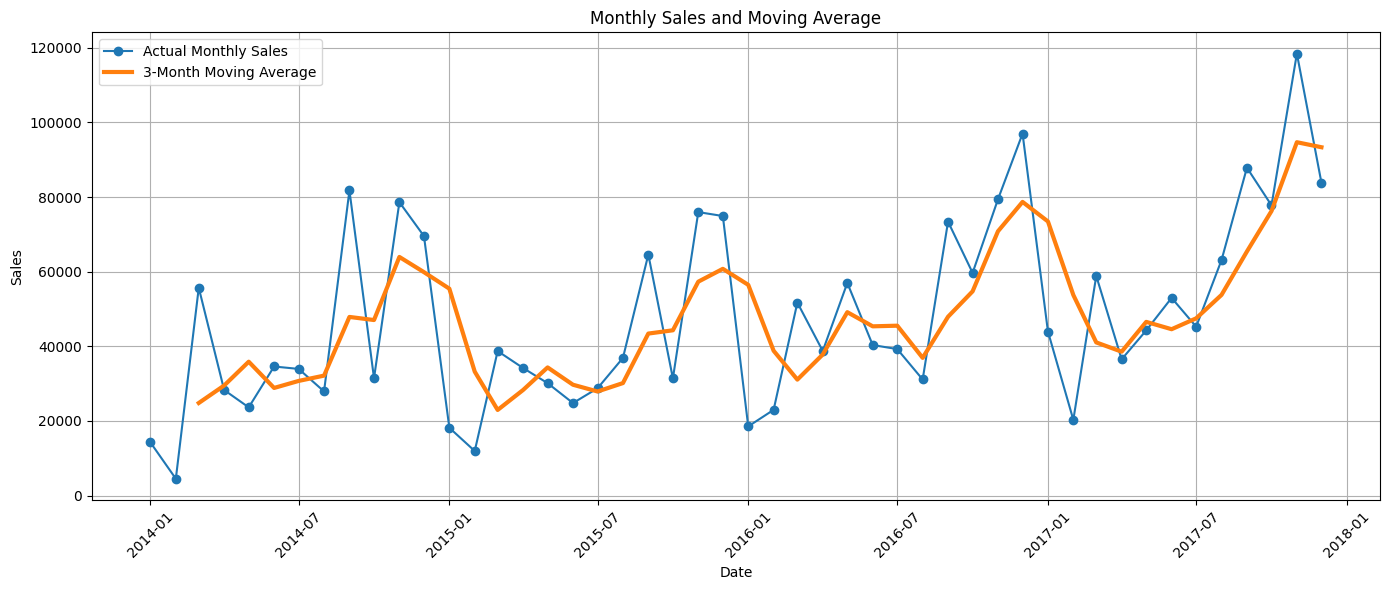

In [72]:

# STEP 5.4: THREE-MONTH MOVING AVERAGE

monthly_sales['Moving_Average'] = (
    monthly_sales['Sales'].rolling(window=3).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Sales'],
    label='Actual Monthly Sales',
    marker='o'
)

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Moving_Average'],
    label='3-Month Moving Average',
    linewidth=3
)

plt.title('Monthly Sales and Moving Average')
plt.xlabel('Date')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [76]:

# STEP 6.1: CREATE LAG FEATURES

ml_data = monthly_sales.copy()

# Previous month's sales
ml_data['Sales_Lag_1'] = ml_data['Sales'].shift(1)

# Sales from two months earlier
ml_data['Sales_Lag_2'] = ml_data['Sales'].shift(2)

# Sales from three months earlier
ml_data['Sales_Lag_3'] = ml_data['Sales'].shift(3)

# Three-month moving average using previous months only
ml_data['Sales_Rolling_Mean_3'] = (
    ml_data['Sales'].shift(1).rolling(window=3).mean()
)

# Remove rows with missing lag values
ml_data = ml_data.dropna().reset_index(drop=True)

print("Lag features created successfully!")

display(ml_data.head(10))

print("\nFinal dataset shape:", ml_data.shape)


Lag features created successfully!


,Year,Month,Sales,Date,Moving_Average,Sales_Lag_1,Sales_Lag_2,Sales_Lag_3,Sales_Rolling_Mean_3
0,2014,4,28295.3450,2014-04-01,29502.082000,55691.0090,4519.8920,14236.8950,24815.932000
1,2014,5,23648.2870,2014-05-01,35878.213667,28295.3450,55691.0090,4519.8920,29502.082000
2,2014,6,34595.1276,2014-06-01,28846.253200,23648.2870,28295.3450,55691.0090,35878.213667
3,2014,7,33946.3930,2014-07-01,30729.935867,34595.1276,23648.2870,28295.3450,28846.253200
4,2014,8,27909.4685,2014-08-01,32150.329700,33946.3930,34595.1276,23648.2870,30729.935867
5,2014,9,81777.3508,2014-09-01,47877.737433,27909.4685,33946.3930,34595.1276,32150.329700
6,2014,10,31453.3930,2014-10-01,47046.737433,81777.3508,27909.4685,33946.3930,47877.737433
7,2014,11,78628.7167,2014-11-01,63953.153500,31453.3930,81777.3508,27909.4685,47046.737433
8,2014,12,69545.6205,2014-12-01,59875.910067,78628.7167,31453.3930,81777.3508,63953.153500
9,2015,1,18174.0756,2015-01-01,55449.470933,69545.6205,78628.7167,31453.3930,59875.910067



Final dataset shape: (45, 9)


In [80]:

# STEP 6.2: SELECT FEATURES AND TARGET

features = [
    'Year',
    'Month',
    'Sales_Lag_1',
    'Sales_Lag_2',
    'Sales_Lag_3',
    'Sales_Rolling_Mean_3'
]

X = ml_data[features]
y = ml_data['Sales']

print("Input features:")
print(features)

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)


Input features:
['Year', 'Month', 'Sales_Lag_1', 'Sales_Lag_2', 'Sales_Lag_3', 'Sales_Rolling_Mean_3']

Feature dataset shape: (45, 6)
Target dataset shape: (45,)


In [84]:

# STEP 6.3: CHRONOLOGICAL TRAIN-TEST SPLIT

split_index = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(ml_data['Date'].iloc[0],
      "to",
      ml_data['Date'].iloc[split_index - 1])

print("\nTesting period:")
print(ml_data['Date'].iloc[split_index],
      "to",
      ml_data['Date'].iloc[-1])


Training records: 36
Testing records: 9

Training period:
2014-04-01 00:00:00 to 2017-03-01 00:00:00

Testing period:
2017-04-01 00:00:00 to 2017-12-01 00:00:00


In [88]:

# STEP 7.1: IMPORT MACHINE LEARNING MODELS

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [92]:

# STEP 7.2: TRAIN LINEAR REGRESSION

# Create model
linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")

print("\nFirst five predictions:")
print(linear_predictions[:5])


Linear Regression trained successfully!

First five predictions:
[42776.7763634  47548.76669258 56040.87527021 58530.15397174
 65230.81239857]


In [96]:

# STEP 7.3: TRAIN RANDOM FOREST

# Create model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=2,
    random_state=42
)

# Train model
random_forest_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest trained successfully!")

print("\nFirst five predictions:")
print(rf_predictions[:5])


Random Forest trained successfully!

First five predictions:
[41390.28961966 42472.06418427 39530.9925965  41854.46358664
 41653.81606551]


In [100]:

# STEP 7.4: MODEL EVALUATION

def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    }


# Evaluate both models
linear_results = evaluate_model(
    y_test,
    linear_predictions,
    'Linear Regression'
)

rf_results = evaluate_model(
    y_test,
    rf_predictions,
    'Random Forest'
)

# Create comparison table
results_df = pd.DataFrame([
    linear_results,
    rf_results
])

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(3))


MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,9972.240,14552.743,0.660
1,Random Forest,14198.662,18360.514,0.459


In [104]:

# STEP 7.5: ACTUAL VS PREDICTED SALES

comparison = pd.DataFrame({
    'Date': ml_data['Date'].iloc[split_index:],
    'Actual Sales': y_test.values,
    'Linear Regression': linear_predictions,
    'Random Forest': rf_predictions
})

display(comparison.round(2))


,Date,Actual Sales,Linear Regression,Random Forest
36,2017-04-01,36521.54,42776.78,41390.29
37,2017-05-01,44261.11,47548.77,42472.06
38,2017-06-01,52981.73,56040.88,39530.99
39,2017-07-01,45264.42,58530.15,41854.46
40,2017-08-01,63120.89,65230.81,41653.82
41,2017-09-01,87866.65,70254.32,63851.19
42,2017-10-01,77776.92,73713.68,61239.51
43,2017-11-01,118447.82,82032.80,79845.28
44,2017-12-01,83829.32,87511.17,80182.34


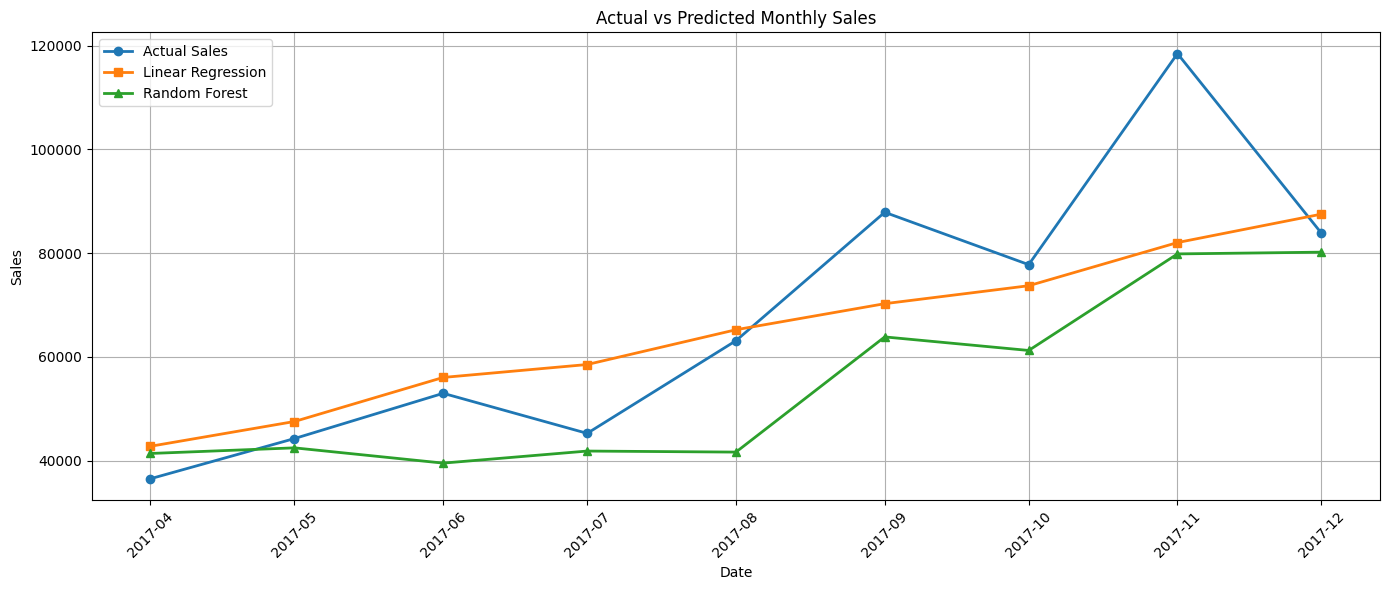

In [108]:

# STEP 8: ACTUAL VS PREDICTED SALES GRAPH

plt.figure(figsize=(14, 6))

plt.plot(
    comparison['Date'],
    comparison['Actual Sales'],
    marker='o',
    label='Actual Sales',
    linewidth=2
)

plt.plot(
    comparison['Date'],
    comparison['Linear Regression'],
    marker='s',
    label='Linear Regression',
    linewidth=2
)

plt.plot(
    comparison['Date'],
    comparison['Random Forest'],
    marker='^',
    label='Random Forest',
    linewidth=2
)

plt.title('Actual vs Predicted Monthly Sales')
plt.xlabel('Date')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [112]:

# STEP 9: DISPLAY MODEL PERFORMANCE

display(results_df.round(3))


,Model,MAE,RMSE,R2 Score
0,Linear Regression,9972.240,14552.743,0.660
1,Random Forest,14198.662,18360.514,0.459


In [116]:

# STEP 10.1: PREPARE FUTURE FORECASTING

def forecast_future(model, historical_data, periods=6):

    history = list(historical_data['Sales'].values)

    last_date = historical_data['Date'].max()

    future_predictions = []

    for i in range(periods):

        next_date = last_date + pd.DateOffset(months=i + 1)

        year = next_date.year
        month = next_date.month

        lag_1 = history[-1]
        lag_2 = history[-2]
        lag_3 = history[-3]

        rolling_mean = np.mean(history[-3:])

        input_data = pd.DataFrame([{
            'Year': year,
            'Month': month,
            'Sales_Lag_1': lag_1,
            'Sales_Lag_2': lag_2,
            'Sales_Lag_3': lag_3,
            'Sales_Rolling_Mean_3': rolling_mean
        }])

        prediction = model.predict(input_data)[0]

        future_predictions.append({
            'Date': next_date,
            'Predicted_Sales': prediction
        })

        history.append(prediction)

    return pd.DataFrame(future_predictions)


print("Forecasting function created successfully!")


Forecasting function created successfully!


In [120]:

# STEP 10.2: GENERATE FUTURE SALES FORECAST

future_forecast = forecast_future(
    linear_model,
    monthly_sales,
    periods=6
)

print("FUTURE SALES FORECAST")

display(future_forecast.round(2))


FUTURE SALES FORECAST


,Date,Predicted_Sales
0,2018-01-01,38826.37
1,2018-02-01,50127.60
2,2018-03-01,49876.12
3,2018-04-01,50459.95
4,2018-05-01,56884.42
5,2018-06-01,61746.51


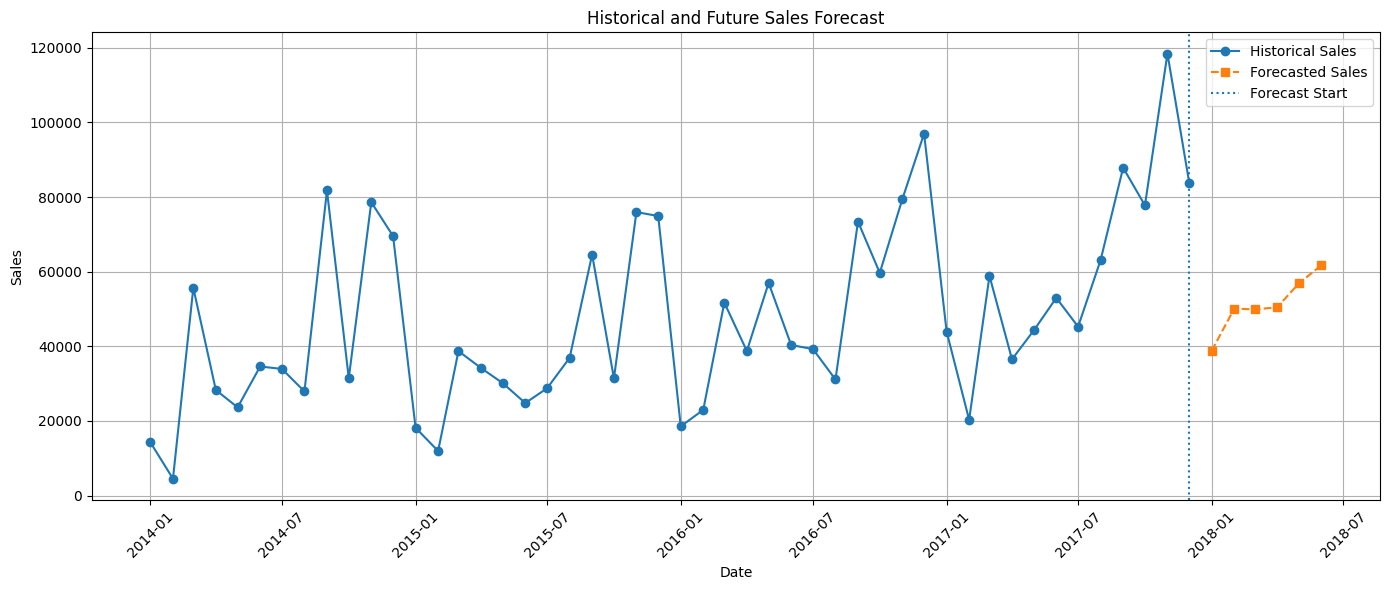

In [124]:

# STEP 10.3: FUTURE SALES FORECAST GRAPH

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Sales'],
    label='Historical Sales',
    marker='o'
)

plt.plot(
    future_forecast['Date'],
    future_forecast['Predicted_Sales'],
    label='Forecasted Sales',
    marker='s',
    linestyle='--'
)

plt.axvline(
    monthly_sales['Date'].max(),
    linestyle=':',
    label='Forecast Start'
)

plt.title('Historical and Future Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [128]:
# Save future sales forecast
future_forecast.to_csv(
    'Future_Sales_Forecast.csv',
    index=False
)

# Download the file
from google.colab import files
files.download('Future_Sales_Forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

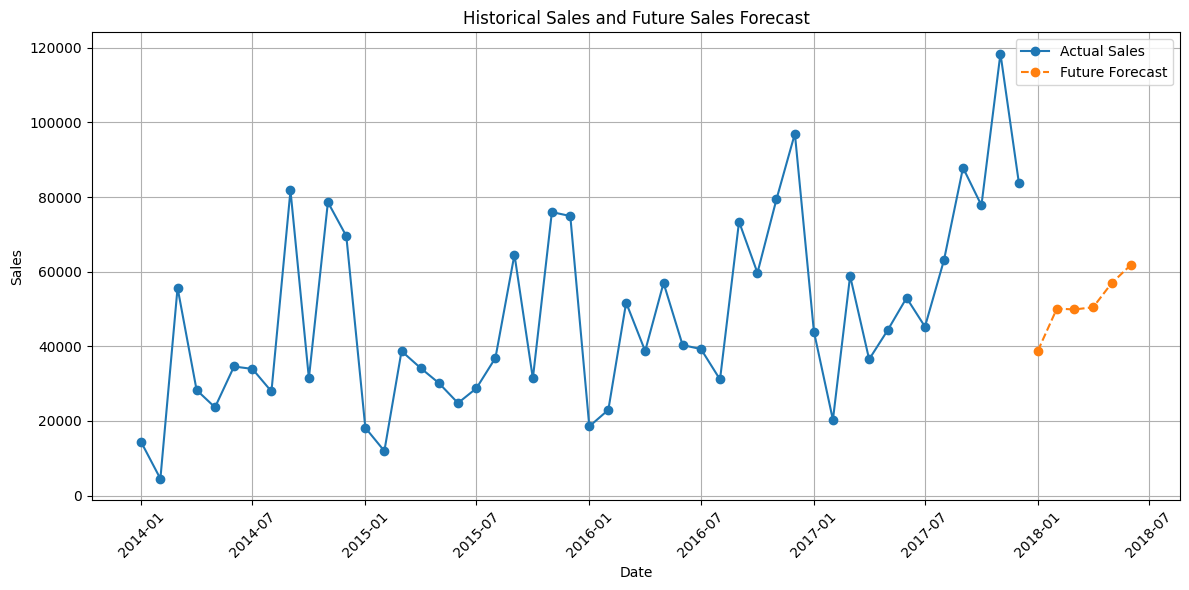

In [132]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Historical monthly sales
plt.plot(
    monthly_sales['Date'],
    monthly_sales['Sales'],
    label='Actual Sales',
    marker='o'
)

# Future predicted sales
plt.plot(
    future_forecast['Date'],
    future_forecast['Predicted_Sales'],
    label='Future Forecast',
    marker='o',
    linestyle='--'
)

plt.title('Historical Sales and Future Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [136]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [9972.240, 14198.662],
    'RMSE': [14552.743, 18360.514],
    'R2 Score': [0.660, 0.459]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,9972.240,14552.743,0.660
1,Random Forest,14198.662,18360.514,0.459


In [137]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


In [138]:

# Check duplicate records

duplicates = df.duplicated().sum()

print("Total duplicate records:", duplicates)


Total duplicate records: 0


In [139]:

# Statistical summary

display(df.describe())


,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Year,Month,Quarter,Day
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,7.809686,2.882329,15.468481
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000,1.000000,1.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,5.000000,2.000000,8.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,9.000000,3.000000,15.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,11.000000,4.000000,23.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,12.000000,4.000000,31.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,3.284654,1.058086,8.748327
